# TUTORIAL <span style="color:orange;">***MASAÏ***</span><img width='64' style="float:right;margin:0 10px 0 20px;" src="images/masai.png" />

Back to the main [Index](Index.ipynb)

## Part 8. 2D EXSY processing

#### Various imports and graphics settings

In [1]:
from __future__ import print_function

#### Loading the <span style="color:orange;">***MASAÏ***</span> library

In [2]:
from masai.api import *

MASAI api loaded: version 0.2.4.9

The current directory is </Users/christian/Dropbox/D.PROGRAMMES/masai/doc/tutorial>
MASAI root directory is </Users/christian/Dropbox/D.PROGRAMMES/masai>


#### Set up the general location of data

In [3]:
import os
# You should set the MASAI environnement variable before running these exemples')
# or change the two following paths according to your installation
DATADIR = os.path.join(MASAI,'doc/tutorial/exemples')
FIGDIR = os.path.join(MASAI,'doc/tutorial/figures')

## Load and plot a 2D fid

In [4]:
user = 'user'
name = 'EXSY'
expno = 451
path = os.path.join(DATADIR, user,'nmr',name, str(expno))
source = Bruker(path) 
source

***Bruker Source***
- path: /Users/christian/Dropbox/D.PROGRAMMES/masai/doc/tutorial/exemples/user/nmr/EXSY/451
- datatype: 2D NMR SER
- pulse program: noesyph
- Encoding: STATES
- TD1: 256, TD2: 6144
- F1 limits: 0.00 to 7.676 ms
- F2 limits: 0.00 to 369.809 ms

In [5]:
#pathpp = os.path.join(source.path,'pulseprogram')
#%load $pathpp

<IPython.core.display.Javascript object>


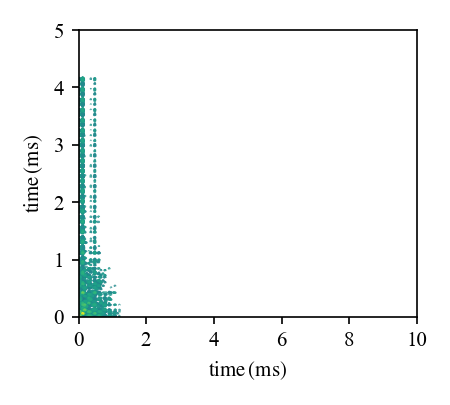

D8 is the mixing time: 100.00 ms


In [7]:
p_2 = Plot2d(source, figsize=(3,2.7), xlim=(0, 10), ylim=(0, 5))  
d8 = float(source.par.D[8])*1000.
print("D8 is the mixing time: %.2f ms"%d8)

## Process SER data

#### Processing

Exponential apodization lb:5.00
Zero-filling to si:16384
Fourier transform with si:16384
clipping along axis -1


<IPython.core.display.Javascript object>


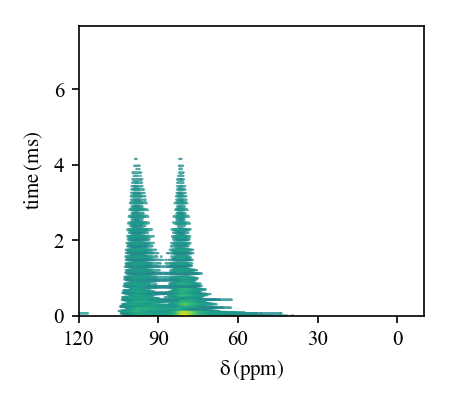

In [22]:
source = Bruker(path) 
Process(source, transform = 'em 5 --k_shifted 1 0')

Process(source, transform = 'zf 1') 
Process(source, transform = 'ft')

Process(source, transform = 'cl -10 120')
#Process(source, transform = 'pk -20 0 --auto --fit_phc1')

p_2 = Plot2d(source, figsize=(3,2.7))

here we display row 0 and 1

Auto-phasing :  phc0 = 2.585, phc1 = -9.951
Phasing phc0:0.58, phc1:-9.95
taking horizontal (axis=1) section by index at index 0


<IPython.core.display.Javascript object>


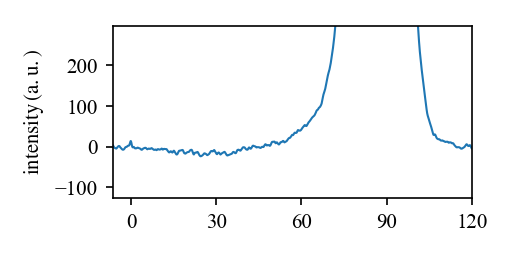

In [29]:
Process(source, transform = 'pk 0 0 --auto --fit_phc1')
Process(source, transform = 'pk -2 0')
row = source.get_row(0, byindex=True)
p_1 = Plot1d(row)

The next step is to perfom a transform in the second dimension 
taking into account the fact that the data are ecquired with the STATES protocols

Exponential apodization lb:5.00
Zero-filling to si:16384
Fourier transform with si:16384
Auto-phasing :  phc0 = 354.142, phc1 = -10.000
Phasing phc0:352.14, phc1:-10.00


<IPython.core.display.Javascript object>


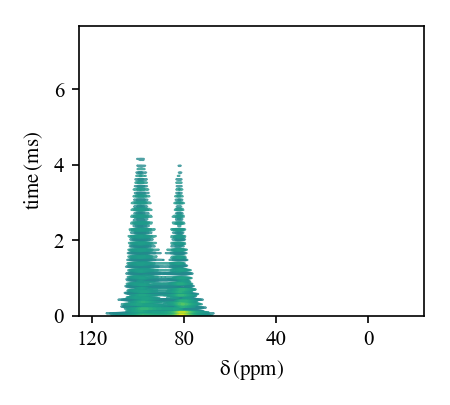

Exponential apodization lb:20.00
Zero-filling to si:256
Data transform according to encoding STATES
Fourier transform with si:256
Phasing phc0:20.37, phc1:-369.10
Auto-phasing :  phc0 = 241.111, phc1 = -9.754


<IPython.core.display.Javascript object>


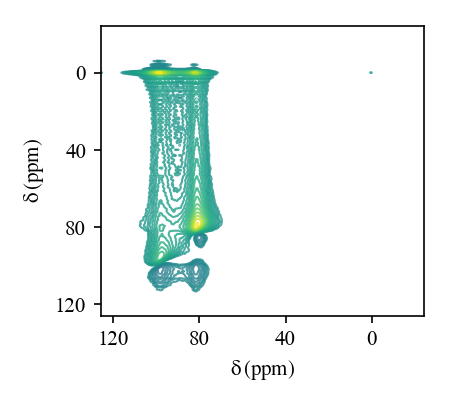

taking vertical (axis=0) section by position from 80.38 to 81.38


<IPython.core.display.Javascript object>


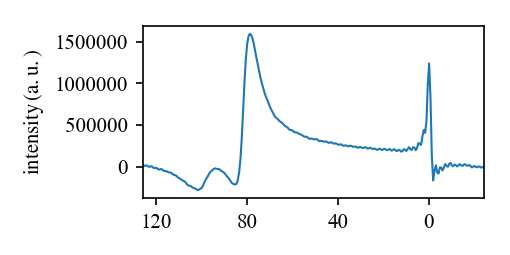

In [31]:
source = Bruker(path) 
Process(source, transform = 'em 5 --k_shifted 1 0')

Process(source, transform = 'zf 1') 
Process(source, transform = 'ft')
Process(source, transform = 'pk 0 0 --auto --fit_phc1')
Process(source, transform = 'pk -2 0')

#p_2 = Plot2d(source, figsize=(3,2.7))

Process(source, axis=0, transform='em 20')
Process(source, axis=0, transform='zf 0') 
Process(source, axis=0, transform='ft')
Process(source, axis=0, transform='pk -65 -200 --auto --select cols --pivot 0.4') #manual phasinf first needed
#Process(source, axis=0, transform='pk 0 0 --auto --fit_phc1 --select cols --pivot 0.4')

p_2 = Plot2d(source, figsize=(3,2.7))

row = source.get_col(80.88,width=1.)
p_1 = Plot1d(row, reverse=True)

Back to the main [Index](Index.ipynb)